In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

tf.keras.utils.set_random_seed(42)

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print(X_train_full.shape, y_train_full.shape)
print(X_test.shape, y_test.shape)
print(np.bincount(y_train_full))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


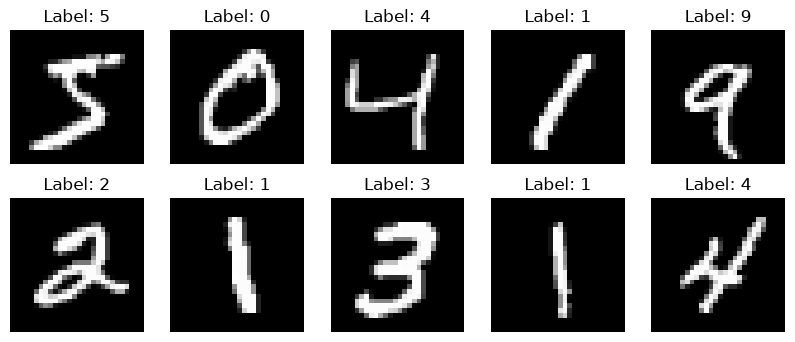

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, img, label in zip(axes.ravel(), X_train_full[:10], y_train_full[:10]):
    ax.imshow(img, cmap='gray')
    ax.set_title(f'Label: {label}')
    ax.axis('off')

plt.show()

In [4]:
X_train_raw = X_train_full.reshape(-1, 784).astype('float32')
X_test_raw = X_test.reshape(-1, 784).astype('float32')

X_tr_raw, X_va_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train_full,
    test_size=0.1,
    random_state=42,
    stratify=y_train_full
)

print(X_tr_raw.shape, X_va_raw.shape)

(54000, 784) (6000, 784)


In [5]:
def build_model(input_dim, hidden_units=(128, 64), activation='relu'):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden_units:
        model.add(layers.Dense(units, activation=activation))

    model.add(layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

def run_experiment(name, X_tr, X_va, hidden_units=(128, 64), activation='relu', epochs=5):
    model = build_model(X_tr.shape[1], hidden_units, activation)

    history = model.fit(X_tr, y_train, epochs=epochs, batch_size=128,
                        validation_data=(X_va, y_val), verbose=0)

    return {
        'Experiment': name,
        'Train Acc': history.history['accuracy'][-1],
        'Val Acc': history.history['val_accuracy'][-1],
        'Val Loss': history.history['val_loss'][-1]
    }

In [6]:
X_tr_norm = X_tr_raw / 255.0
X_va_norm = X_va_raw / 255.0

mean = X_tr_raw.mean()
std = X_tr_raw.std()

X_tr_std = (X_tr_raw - mean) / std
X_va_std = (X_va_raw - mean) / std

results = []

results.append(run_experiment('Preprocessing: raw (0-255)', X_tr_raw, X_va_raw))
results.append(run_experiment('Preprocessing: normalized (/255)', X_tr_norm, X_va_norm))
results.append(run_experiment('Preprocessing: standardized', X_tr_std, X_va_std))

pd.DataFrame(results).round(4)

,Experiment,Train Acc,Val Acc,Val Loss
0,Preprocessing: raw (0-255),0.9549,0.9445,0.2994
1,Preprocessing: normalized (/255),0.9834,0.9717,0.1033
2,Preprocessing: standardized,0.9859,0.9717,0.1029


In [7]:
keep = X_tr_norm.std(axis=0) > 0

print(f'Pixels kept: {keep.sum()} of {len(keep)}')

results.append(run_experiment('Feature selection: drop constant pixels', X_tr_norm[:, keep], X_va_norm[:, keep]))

pd.DataFrame(results).round(4)

Pixels kept: 713 of 784


,Experiment,Train Acc,Val Acc,Val Loss
0,Preprocessing: raw (0-255),0.9549,0.9445,0.2994
1,Preprocessing: normalized (/255),0.9834,0.9717,0.1033
2,Preprocessing: standardized,0.9859,0.9717,0.1029
3,Feature selection: drop constant pixels,0.9821,0.9737,0.0982


In [8]:
for units in [(64,), (128, 64), (256, 128, 64)]:
    results.append(run_experiment(f'Architecture: {units}', X_tr_norm, X_va_norm, hidden_units=units))

pd.DataFrame(results).round(4)

,Experiment,Train Acc,Val Acc,Val Loss
0,Preprocessing: raw (0-255),0.9549,0.9445,0.2994
1,Preprocessing: normalized (/255),0.9834,0.9717,0.1033
2,Preprocessing: standardized,0.9859,0.9717,0.1029
3,Feature selection: drop constant pixels,0.9821,0.9737,0.0982
4,"Architecture: (64,)",0.9686,0.9608,0.1409
5,"Architecture: (128, 64)",0.9821,0.9710,0.1031
6,"Architecture: (256, 128, 64)",0.9875,0.9718,0.1023


In [9]:
for act in ['relu', 'tanh', 'sigmoid']:
    results.append(run_experiment(f'Activation: {act}', X_tr_norm, X_va_norm, activation=act))

summary = pd.DataFrame(results)

summary.round(4)

,Experiment,Train Acc,Val Acc,Val Loss
0,Preprocessing: raw (0-255),0.9549,0.9445,0.2994
1,Preprocessing: normalized (/255),0.9834,0.9717,0.1033
2,Preprocessing: standardized,0.9859,0.9717,0.1029
3,Feature selection: drop constant pixels,0.9821,0.9737,0.0982
4,"Architecture: (64,)",0.9686,0.9608,0.1409
5,"Architecture: (128, 64)",0.9821,0.9710,0.1031
6,"Architecture: (256, 128, 64)",0.9875,0.9718,0.1023
7,Activation: relu,0.9828,0.9685,0.1093
8,Activation: tanh,0.9806,0.9688,0.1085
9,Activation: sigmoid,0.9591,0.9558,0.1569


In [10]:
model = build_model(784, hidden_units=(128, 64), activation='relu')

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_tr_norm, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(X_va_norm, y_val),
    callbacks=[early_stop]
)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9019 - loss: 0.3459 - val_accuracy: 0.9467 - val_loss: 0.1906
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9578 - loss: 0.1460 - val_accuracy: 0.9608 - val_loss: 0.1423
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9701 - loss: 0.1031 - val_accuracy: 0.9670 - val_loss: 0.1228
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9778 - loss: 0.0778 - val_accuracy: 0.9695 - val_loss: 0.1118
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9829 - loss: 0.0602 - val_accuracy: 0.9720 - val_loss: 0.1034
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9860 - loss: 0.0477 - val_accuracy: 0.9722 - val_loss: 0.1012
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9897 - loss: 0.0377 - val_accuracy: 0.9732 - val_loss: 0.1035
Epoch 8/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9918 - loss: 0.0304 - val_accuracy: 0.

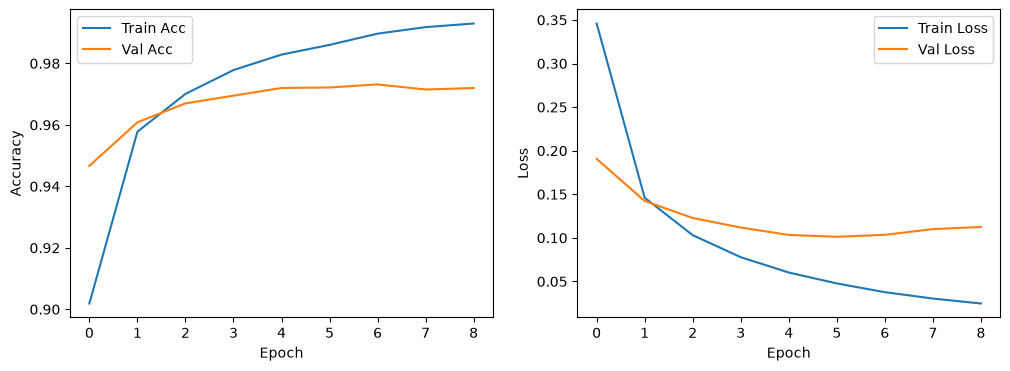

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='Train Acc')
ax[0].plot(history.history['val_accuracy'], label='Val Acc')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()

ax[1].plot(history.history['loss'], label='Train Loss')
ax[1].plot(history.history['val_loss'], label='Val Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()

plt.show()

In [12]:
X_test_norm = X_test_raw / 255.0

test_loss, test_acc = model.evaluate(X_test_norm, y_test, verbose=0)

print(f'Test Loss: {test_loss}')
print(f'Test Accuracy: {test_acc}')

Test Loss: 0.08347922563552856
Test Accuracy: 0.9750999808311462


In [13]:
y_pred_prob = model.predict(X_test_norm, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9710    0.9918    0.9813       980
           1     0.9903    0.9903    0.9903      1135
           2     0.9664    0.9758    0.9711      1032
           3     0.9695    0.9752    0.9724      1010
           4     0.9698    0.9807    0.9752       982
           5     0.9773    0.9675    0.9724       892
           6     0.9883    0.9687    0.9784       958
           7     0.9711    0.9796    0.9753      1028
           8     0.9596    0.9743    0.9669       974
           9     0.9876    0.9445    0.9656      1009

    accuracy                         0.9751     10000
   macro avg     0.9751    0.9748    0.9749     10000
weighted avg     0.9752    0.9751    0.9751     10000



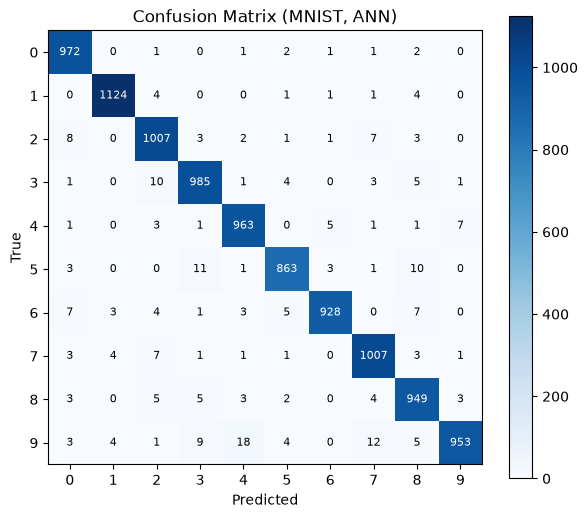

In [14]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (MNIST, ANN)')

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.show()

Misclassified: 249 of 10000


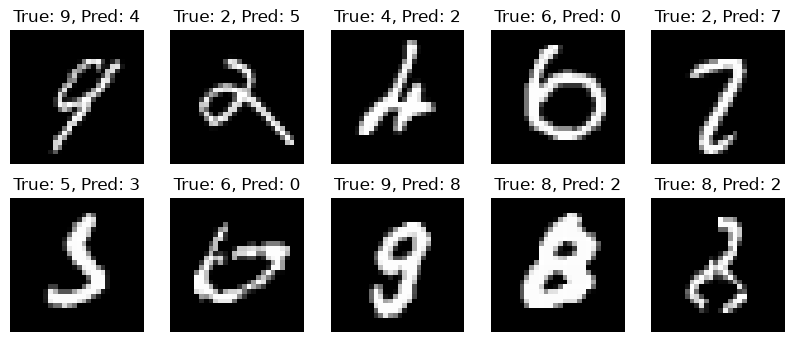

In [15]:
wrong = np.where(y_pred != y_test)[0]

print(f'Misclassified: {len(wrong)} of {len(y_test)}')

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, i in zip(axes.ravel(), wrong[:10]):
    ax.imshow(X_test[i], cmap='gray')
    ax.set_title(f'True: {y_test[i]}, Pred: {y_pred[i]}')
    ax.axis('off')

plt.show()

### Analysis – Lab Assignment

**Answer:** Normalizing the input is the most important step (validation accuracy 0.9445 raw vs 0.9717 normalized). Dropping constant pixels helps only slightly (0.9737), a second hidden layer helps (0.9608 to 0.9710), a third adds nothing, and sigmoid (0.9558) is worse than ReLU and tanh (about 0.9685). The final model (128-64 ReLU, normalized input, early stopping) reaches a test accuracy of **0.9751**. Digit 9 is the hardest, mostly confused with 4 and 7.